# Industry Classification Using Business Description Embeddings and Financial Data

This notebook follows the current course skeleton. It compares logistic regression
and k-nearest neighbors, then combines their predictions and learns confidence
using text and financial information. No new embeddings or GPU are needed.

**Verified execution:** all 14 code cells ran on the supplied 31,706 records,
producing eight plots. On 3,171 final validation records, the ensemble achieved
78.09% weighted F1 and a 67.50% official confidence score. The 85% target was not
reached. Full execution with verification took 81.5 seconds in the cloud.

Run every cell in order from a fresh kernel. Put the two supplied pickle files in
`data/`, beside this notebook. The private test set is unavailable, so no private
score or bonus award is claimed. Beginner explanations are in `EXPLANATION.md`.


In [1]:
import ast
from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import GroupShuffleSplit
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import LabelEncoder
from threadpoolctl import threadpool_limits

threadpool_limits(limits=2)
started = perf_counter()


# Loading Data

Financial rows are linked by company `id`. Some IDs occur twice: the median
gives one robust value per company and avoids choosing an arbitrary first row.
This uses only that company's records, not industry labels or other companies.
Infinities become missing values. Valid negative values are retained.


In [2]:
financial_columns = ['net_profit_margin', 'ebitda_margin', 'asset_turnover']
financials = pd.read_pickle('data/df_financials_train.pkl')
display(pd.DataFrame({
    'Missing values': financials[financial_columns].isna().sum(),
    'Infinite values': np.isinf(financials[financial_columns]).sum()
}))
print('Repeated financial IDs:', financials['id'].duplicated().sum())
financials = financials.replace([np.inf, -np.inf], np.nan)
financials = financials.groupby('id')[financial_columns].median()


,Missing values,Infinite values
net_profit_margin,1111,2131
ebitda_margin,19279,824
asset_turnover,1363,5


Repeated financial IDs: 162


Keep approximately 10% of companies for final validation. Split the remaining
90% into approximately 81% for fitting models and 9% held out from fitting.
Split that held-out portion equally into 4.5% for choosing settings and 4.5%
for learning confidence. Final validation is kept separate from both purposes.
`GroupShuffleSplit` keeps repeated company IDs together, because one company
has two different embedding records. `random_state=42` makes this repeatable.

A many-to-one join checks that finances contain at most one row per company ID.
Companies without financial records remain in the dataset.


In [3]:
df = pd.read_pickle('data/df_train.pkl')
df = df.merge(financials, on='id', how='left', validate='many_to_one')
splitter = GroupShuffleSplit(n_splits=1, test_size=0.1, random_state=42)
train_index, val_index = next(splitter.split(df, groups=df['id']))
df_train, df_val = df.iloc[train_index], df.iloc[val_index]
fit_index, development_index = next(splitter.split(df_train, groups=df_train['id']))
df_fit, df_development = df_train.iloc[fit_index], df_train.iloc[development_index]
tune_index, cal_index = next(GroupShuffleSplit(n_splits=1, test_size=0.5, random_state=42).split(
    df_development, groups=df_development['id']))
df_tune, df_cal = df_development.iloc[tune_index], df_development.iloc[cal_index]
print('Companies:', len(df), '| fitting:', len(df_fit),
      '| tuning:', len(df_tune), '| calibration:', len(df_cal), '| validation:', len(df_val))

def embeddings(companies):
    return np.array(companies['business_description_embedding'].apply(ast.literal_eval).tolist(), dtype=np.float32)

X_fit = embeddings(df_fit)
X_tune = embeddings(df_tune)
X_cal = embeddings(df_cal)
X_val = embeddings(df_val)
print('Embedding dimensions:', X_fit.shape[1])


Companies: 31706 | fitting: 25681 | tuning: 1427 | calibration: 1427 | validation: 3171


Embedding dimensions: 768


# Transforming Data (Label Encoding)

### Tasks:
- Use the scikit-learn label encoder to encode the industry names
- Check if all classes contained in the validation set are also in the training set


`LabelEncoder` assigns each industry an integer. Fit the mapping using fitting
companies only, and reuse it for all held-out sets. The assertion checks that
every held-out industry has fitting examples.


In [4]:
le = LabelEncoder().fit(df_fit['industry'])
assert set(df_tune['industry']).union(df_cal['industry'], df_val['industry']).issubset(le.classes_)
y_fit = le.transform(df_fit['industry'])
y_tune = le.transform(df_tune['industry'])
y_cal = le.transform(df_cal['industry'])
y_val = le.transform(df_val['industry'])
print('Industries:', len(le.classes_), '| all held-out industries occur in fitting data')


Industries: 25 | all held-out industries occur in fitting data


# Visualize the data


### Tasks:
- Are certain classes over- or under represented? Either produce a table or a plot to show this.
- Inspect whether there is signal in the business description embeddings:
    - Perform a PCA to project data into 2 dimensions
    - Plot projected data in Scatterplot and color based on classes
    - Provide a description of what you see and judge whether there is signal in the data that allows industry classification

Important: Ensure that your plots have proper axis descriptions and titles. Style the plots so that differences in class distributions are visible (e.g. scatter size, transparency, color, etc.)


### Class distribution

Count industries in the training portion. The smallest/largest counts and
largest share describe imbalance without assuming what the results will be.


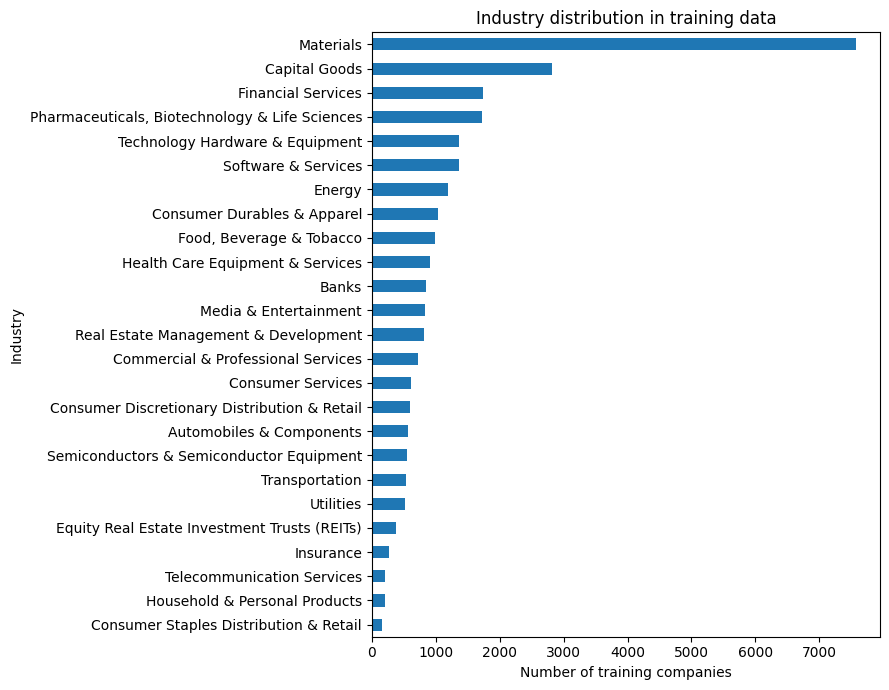

Smallest industry: Consumer Staples Distribution & Retail 160
Largest industry: Materials 7570 | share: 26.5%


In [5]:
counts = df_train['industry'].value_counts()
counts.sort_values().plot.barh(figsize=(9, 7))
plt.xlabel('Number of training companies')
plt.ylabel('Industry')
plt.title('Industry distribution in training data')
plt.tight_layout()
plt.show()
print('Smallest industry:', counts.idxmin(), counts.min())
print('Largest industry:', counts.idxmax(), counts.max(),
      '| share:', f'{counts.max() / counts.sum():.1%}')


### PCA — dimensionality reduction and visualization

Fit PCA on fitting embeddings only. Keep 128 components to make k-NN distances
cheaper; the first two give the required scatterplot. Logistic regression
retains the original embeddings. Both models use the same companies.

A small development comparison favored 128 components over 64 and all 768.
The printed explained variance shows how much variation this projection keeps.
Overlap in two dimensions does not establish overlap in all embedding dimensions.


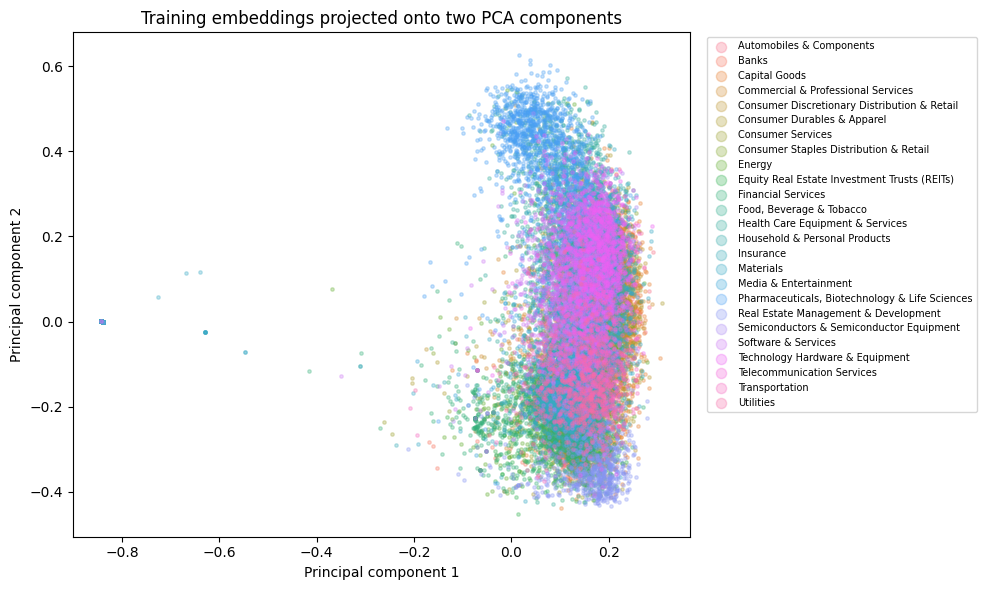

Variance retained by 2 components: 25.3%
Variance retained by 128 components: 87.6%


In [6]:
model_started = perf_counter()
pca = PCA(n_components=128, random_state=42)
X_fit_pca = pca.fit_transform(X_fit)
X_tune_pca = pca.transform(X_tune)
X_cal_pca = pca.transform(X_cal)
X_val_pca = pca.transform(X_val)
pca_seconds = perf_counter() - model_started

colors = sns.color_palette('husl', len(le.classes_))
fig, ax = plt.subplots(figsize=(10, 6))
for label, industry in enumerate(le.classes_):
    mask = y_fit == label
    ax.scatter(X_fit_pca[mask, 0], X_fit_pca[mask, 1],
               s=6, alpha=0.3, color=colors[label], label=industry)
ax.set(xlabel='Principal component 1', ylabel='Principal component 2',
       title='Training embeddings projected onto two PCA components')
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=7, markerscale=3)
plt.tight_layout()
plt.show()
print('Variance retained by 2 components:', f'{pca.explained_variance_ratio_[:2].sum():.1%}')
print('Variance retained by 128 components:', f'{pca.explained_variance_ratio_.sum():.1%}')


# Fitting and comparing Classifier Models


### Tasks:
- Split the data into train and validation data
- Encode the industry labels using LabelEncoder (scikit-learn)
- Fit a LogisticRegression and a kNN-classifier
- Compare the model performance of both models:
    - Compute Accuracy and F1 score
        - Interpret the scores: Explain how they are computed and judge if your model performs well
        - Analyze the classification errors: 
            - Do the errors correlate with how well classes are represented?
            - Which industries does the model identify well and which seem to be similar?
    - Plot a confusion matrix for both models (combine scikit-learn confusion matrix and seaborn heatmap plot)
    - Do both models misclassify the same examples?

Import: Use proper axis labels for the plots!


Logistic regression learns industry weights from all embedding coordinates.
k-NN uses the 128 PCA coordinates and distance-weighted votes from 15 neighbors.
Small tuning-only comparisons checked C=1, 10, 100, and 1000, and 5, 15, or 25
neighbors. C=1 had the strongest standalone logistic-regression result, but
C=10 combined better with the selected 128-component, 15-neighbor k-NN.
The joint prediction result determines this choice; tuning companies remain
separate from confidence calibration and final validation.
Class weighting and extra scaling are omitted because their benefit is unmeasured.

Both models and PCA remain frozen after fitting, so calibration companies are
unseen by the base classifiers. Cached probabilities avoid repeating expensive
k-NN prediction when comparing confidence methods.


In [7]:
lr = LogisticRegression(C=10, max_iter=1000)
knn = KNeighborsClassifier(n_neighbors=15, weights='distance', n_jobs=2)
model_started = perf_counter()
lr.fit(X_fit, y_fit)
knn.fit(X_fit_pca, y_fit)
print('PCA and classifier fitting seconds:', round(pca_seconds + perf_counter() - model_started, 1))

proba_tune_lr = lr.predict_proba(X_tune)
proba_tune_knn = knn.predict_proba(X_tune_pca)
weights = [0.25, 0.5, 0.75]
tuning_f1 = [f1_score(y_tune, (weight * proba_tune_lr + (1 - weight) * proba_tune_knn).argmax(axis=1),
                      average='weighted') for weight in weights]
lr_weight = weights[np.argmax(tuning_f1)]
display(pd.DataFrame({'Logistic regression weight': weights, 'Tuning weighted F1': tuning_f1}))
print('Selected logistic regression weight:', lr_weight)

proba_cal_lr = lr.predict_proba(X_cal)
proba_cal_knn = knn.predict_proba(X_cal_pca)
proba_val_lr = lr.predict_proba(X_val)
proba_val_knn = knn.predict_proba(X_val_pca)
predictions = {'Logistic regression': proba_val_lr.argmax(axis=1),
               'k-NN': proba_val_knn.argmax(axis=1)}


PCA and classifier fitting seconds: 12.1


,Logistic regression weight,Tuning weighted F1
0,0.25,0.791847
1,0.50,0.783686
2,0.75,0.782247


Selected logistic regression weight: 0.25


Accuracy is the fraction of correct predictions. For one industry, TP counts
correct predictions, FP counts other industries predicted as this one, and FN
counts its companies predicted as another industry. Precision is TP/(TP+FP),
recall is TP/(TP+FN), and F1 is 2 × precision × recall / (precision + recall).
Weighted F1 averages class F1 using each class's validation support; macro F1
gives every industry equal weight. Undefined per-class divisions use zero.
A negative correlation between support and error rate suggests larger industries
have fewer errors, but correlation alone does not establish the cause.

Confusion matrices are normalized by true industry so rare industries remain
visible. The printed confusion pairs use raw counts.


Logistic regression


,precision,recall,f1-score,support
Commercial & Professional Services,0.490196,0.304878,0.375940,82.0
Household & Personal Products,0.470588,0.421053,0.444444,19.0
Consumer Staples Distribution & Retail,0.428571,0.500000,0.461538,18.0
Consumer Discretionary Distribution & Retail,0.612245,0.526316,0.566038,57.0
Capital Goods,0.639241,0.655844,0.647436,308.0
Technology Hardware & Equipment,0.702532,0.627119,0.662687,177.0
Telecommunication Services,0.615385,0.727273,0.666667,22.0
Software & Services,0.682081,0.706587,0.694118,167.0
Semiconductors & Semiconductor Equipment,0.745455,0.650794,0.694915,63.0
Energy,0.750000,0.647482,0.694981,139.0


Industry size / error-rate correlation: -0.362


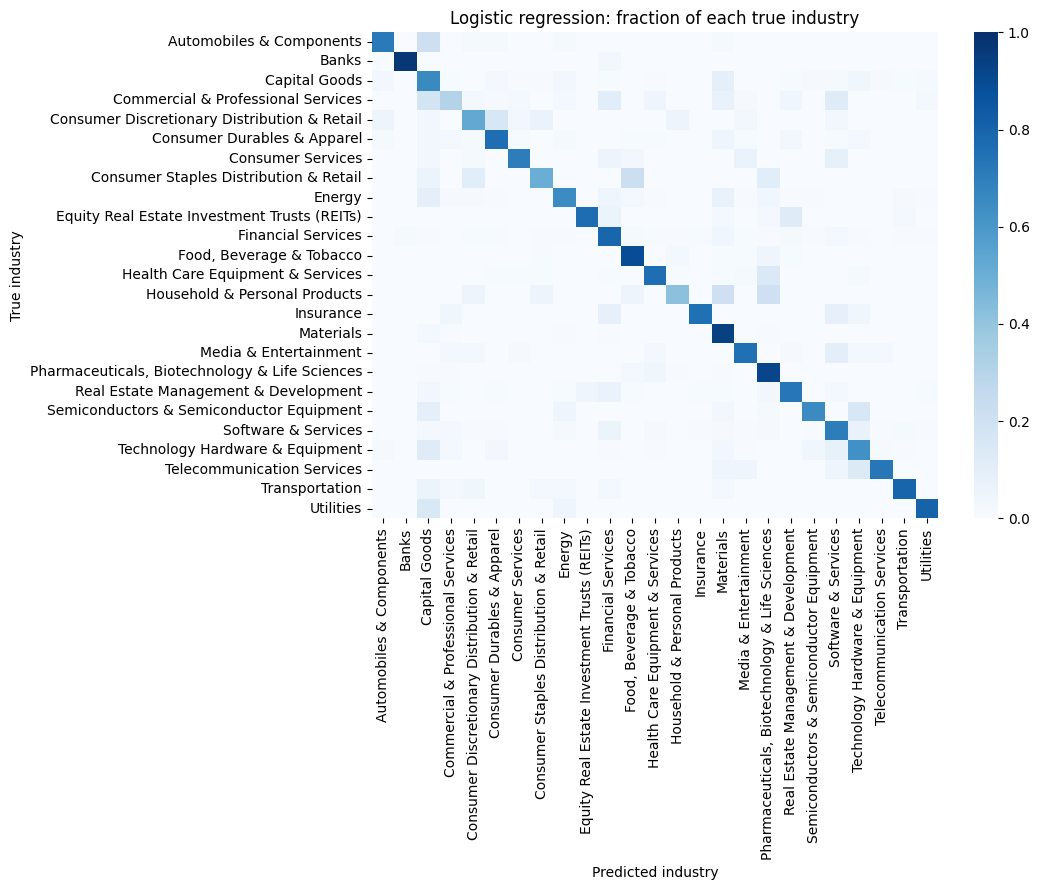

Capital Goods                       Materials                                         28
Technology Hardware & Equipment     Capital Goods                                     21
Materials                           Capital Goods                                     18
Health Care Equipment & Services    Pharmaceuticals, Biotechnology & Life Sciences    15
Commercial & Professional Services  Capital Goods                                     15
Name: Misclassifications, dtype: int64

k-NN


,precision,recall,f1-score,support
Commercial & Professional Services,0.612903,0.231707,0.336283,82.0
Consumer Staples Distribution & Retail,0.600000,0.333333,0.428571,18.0
Household & Personal Products,0.416667,0.526316,0.465116,19.0
Consumer Discretionary Distribution & Retail,0.574074,0.543860,0.558559,57.0
Capital Goods,0.619938,0.646104,0.632750,308.0
Semiconductors & Semiconductor Equipment,0.740741,0.634921,0.683761,63.0
Technology Hardware & Equipment,0.723926,0.666667,0.694118,177.0
Energy,0.809524,0.611511,0.696721,139.0
Software & Services,0.733766,0.676647,0.704050,167.0
Real Estate Management & Development,0.673267,0.739130,0.704663,92.0


Industry size / error-rate correlation: -0.284


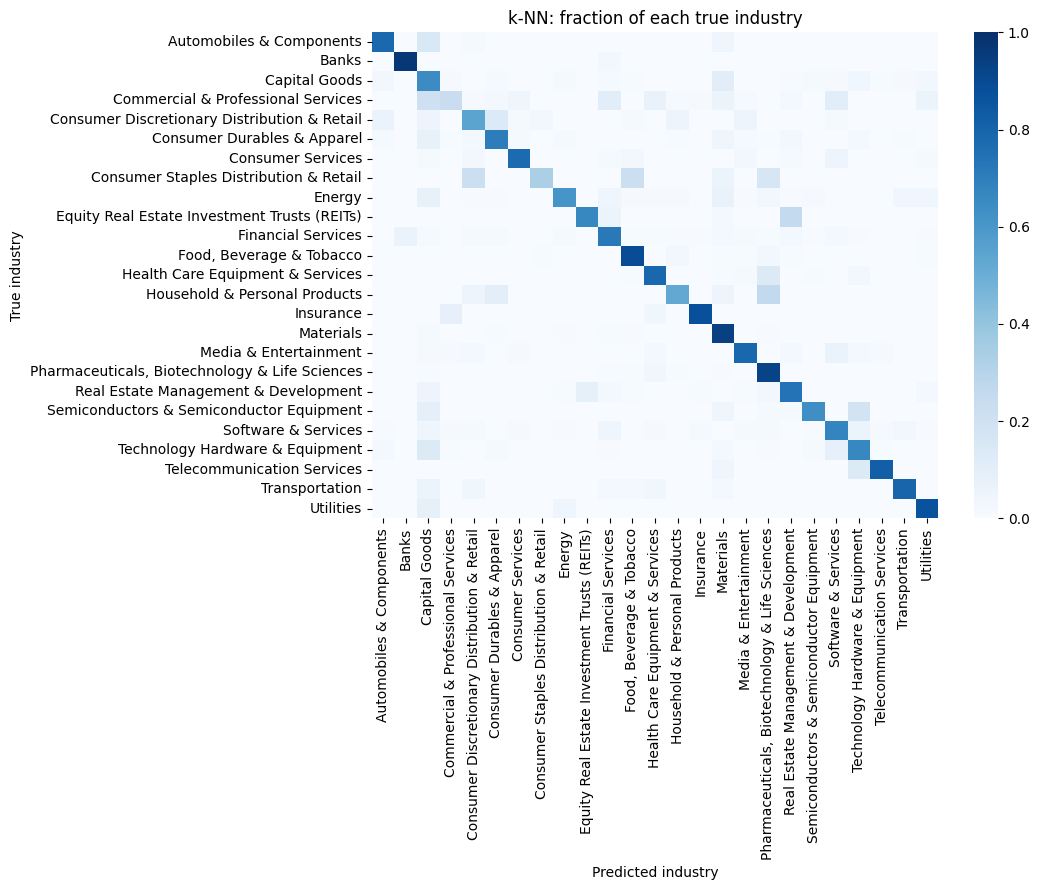

Capital Goods                       Materials              33
Technology Hardware & Equipment     Capital Goods          24
Commercial & Professional Services  Capital Goods          17
Materials                           Capital Goods          16
Technology Hardware & Equipment     Software & Services    15
Name: Misclassifications, dtype: int64

,Accuracy,Weighted F1,Macro F1
Model,,,
Logistic regression,0.781457,0.777788,0.717515
k-NN,0.777042,0.771401,0.710471


Higher validation weighted F1: Logistic regression
Both models wrong: 520
Only logistic regression wrong: 173
Only k-NN wrong: 187


In [8]:
results = []
for name, prediction in predictions.items():
    results.append([name, accuracy_score(y_val, prediction),
                    f1_score(y_val, prediction, average='weighted'),
                    f1_score(y_val, prediction, average='macro')])
    report = pd.DataFrame(classification_report(
        y_val, prediction, labels=np.arange(len(le.classes_)),
        target_names=le.classes_, output_dict=True, zero_division=0
    )).T.loc[le.classes_]
    print(name)
    display(report.sort_values('f1-score'))
    print('Industry size / error-rate correlation:',
          round(counts.reindex(report.index).corr(1 - report['recall']), 3))
    cm = confusion_matrix(y_val, prediction, labels=np.arange(len(le.classes_)), normalize='true')
    plt.figure(figsize=(11, 9))
    sns.heatmap(cm, xticklabels=le.classes_, yticklabels=le.classes_,
                cmap='Blues', vmin=0, vmax=1)
    plt.xlabel('Predicted industry')
    plt.ylabel('True industry')
    plt.title(name + ': fraction of each true industry')
    plt.tight_layout()
    plt.show()
    pairs = pd.DataFrame(confusion_matrix(y_val, prediction, labels=np.arange(len(le.classes_))),
                         index=le.classes_, columns=le.classes_)
    np.fill_diagonal(pairs.values, 0)
    display(pairs.stack().sort_values(ascending=False).head(5).rename('Misclassifications'))

comparison = pd.DataFrame(results, columns=['Model', 'Accuracy', 'Weighted F1', 'Macro F1']).set_index('Model')
display(comparison)
print('Higher validation weighted F1:', comparison['Weighted F1'].idxmax())
errors_lr = predictions['Logistic regression'] != y_val
errors_knn = predictions['k-NN'] != y_val
print('Both models wrong:', np.sum(errors_lr & errors_knn))
print('Only logistic regression wrong:', np.sum(errors_lr & ~errors_knn))
print('Only k-NN wrong:', np.sum(~errors_lr & errors_knn))


### Interpretation of the mandatory results

**Imbalance and PCA.** Materials has 7,570 training records (26.5%), while
Consumer Staples Distribution & Retail has 160: a roughly 47-fold difference.
The PCA plot shows some concentrations, including the upper pharmaceutical
cluster, but substantial overlap among industries in the central region. Its
first two components retain only 25.3% of embedding variance; all 128 retain
87.6%. Two-dimensional overlap does not prove full-dimensional inseparability.

**Classifier comparison.** Logistic regression is the stronger required classifier
on this validation: 78.15% accuracy and 77.78% weighted F1, compared with k-NN's
77.70% and 77.14%. Macro F1 is lower (71.75% and 71.05%), indicating weaker
performance when small industries have equal influence. Logistic-regression F1
is 97.17% for Banks and 92.43% for Materials, but 37.59% for Commercial &
Professional Services, 44.44% for Household & Personal Products, and 46.15%
for Consumer Staples Distribution & Retail. Rare-class estimates use few cases.

**Representation and similarity.** Industry-size/error-rate correlations are
−0.362 for logistic regression and −0.284 for k-NN. Larger industries tend to
have fewer errors, but size is not a complete explanation: Commercial &
Professional Services has 722 training records and remains the weakest class.
Both models often confuse Capital Goods with Materials (28 and 33 cases) and
Technology Hardware & Equipment with Capital Goods (21 and 24). These pairs
are consistent with related business activities, though counts alone cannot
establish the descriptions' precise similarities or causes of error.

**Complementary errors.** Both models are wrong on 520 records; 173 errors are
unique to logistic regression and 187 to k-NN. Their mistakes overlap heavily,
but some complementary predictions help the ensemble reach 78.09% weighted F1,
a 0.31-percentage-point gain over the stronger standalone classifier.


# Optional: Confidence Weighted Prediction

## Deliverables:

- Provide a notebook with the implementation and training of an industry classifier model
- The model shall output the industry classification and its confidence as a tuple of vectors $(\hat{y}_{pred}, \hat{y}_{confidence})$
- The confidence score must be between 0 and 1, $\hat{y}_{confidence} [i] \in [0,1]$
- Your model will be evaluated on a private test set
- Designing the confidence score is your task. You may use p-values, a voting mechanism of multiple models, or other techniques
- Another option is to add more features, e.g. financial data, to X

## Scoring

Your submission is scored with the function `confidence_score` below:

$$\text{score} = F_1^{\text{weighted}}(y, \hat{y}_{pred}) \cdot \left(1 - \text{Brier}\right), \qquad \text{Brier} = \frac{1}{n}\sum_{i=1}^{n} \left(\hat{y}_{confidence}[i] - \mathbb{1}[\hat{y}_{pred}[i] = y_i]\right)^2$$

- **Weighted F1** measures how good your predicted industries are (the confidence does not enter here).
- **Brier score** measures how good your confidence is: $\hat{y}_{confidence}[i]$ should be the probability that prediction $i$ is correct.
- The Brier term is smallest when your confidence is *calibrated*: among all predictions with confidence 0.8, about 80% should be correct.
- Always reporting confidence 1.0 does not pay off (every wrong prediction costs the maximum penalty), and neither does reporting very low confidence everywhere.


This is the course's exact scoring function. Its weighted F1 uses industry
frequencies, not confidence weights. The Brier term compares confidence with
correctness (1 if correct, 0 otherwise). Arbitrarily shrinking confidence to the
sixth power, as in the older solution, does not follow this scoring objective.


In [9]:
def confidence_score(y_true, y_pred, confidence):
    """
    Score for the confidence weighted prediction task.

    Parameters:
    -----------
    y_true : array-like
        True class labels
    y_pred : array-like
        Predicted class labels
    confidence : array-like
        Confidence for each prediction, in [0, 1]
        (= estimated probability that the prediction is correct)

    Returns:
    --------
    float
        weighted F1 * (1 - Brier score), between 0 and 1 (higher is better)
    """
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    confidence = np.asarray(confidence, dtype=float)

    assert len(y_true) == len(y_pred) == len(confidence), "Inputs must have the same length"
    assert np.all((confidence >= 0) & (confidence <= 1)), "Confidence must be between 0 and 1"

    f1 = f1_score(y_true, y_pred, average="weighted")
    correct = (y_true == y_pred).astype(float)
    brier = np.mean((confidence - correct) ** 2)

    return f1 * (1 - brier)


### Financial distributions

Show training-only distributions of all three ratios. Boxplots display medians
and middle ranges. Hiding plotted outlier dots does not delete the observations.
A symmetric logarithmic axis displays large magnitudes and negative values.
The financial confidence signal below uses ranks, so extreme magnitudes have
bounded influence without assuming normal or log-normal distributions.


net_profit_margin            \
                                                           count    median   
industry                                                                     
Automobiles & Components                                     475  0.034077   
Banks                                                        710  0.245811   
Capital Goods                                               2276  0.039592   
Commercial & Professional Services                           532  0.033262   
Consumer Discretionary Distribution & Retail                 473  0.017686   
Consumer Durables & Apparel                                  832  0.031132   
Consumer Services                                            469  0.028669   
Consumer Staples Distribution & Retail                       140  0.022693   
Energy                                                       795  0.043417   
Equity Real Estate Investment Trusts (REITs)                 323  0.252600   
Financial Services                                          1115  0.259259   
Food, Beverage & Tobacco                                     782  0.038511   
Health Care Equipment & Services                             678 -0.003701   
Household & Personal Products                                161  0.035555   
Insurance                                                    211  0.079118   
Materials                                                   5438  0.049562   
Media & Entertainment                                        620 -0.021711   
Pharmaceuticals, Biotechnology & Life Sciences              1074 -0.188698   
Real Estate Management & Development                         636  0.080751   
Semiconductors & Semiconductor Equipment                     457  0.042345   
Software & Services                                         1012  0.002503   
Technology Hardware & Equipment                             1144  0.025385   
Telecommunication Services                                   154  0.033975   
Transportation                                               434  0.070571   
Utilities                                                    414  0.085487   

                                               ebitda_margin            \
                                                       count    median   
industry                                                                 
Automobiles & Components                                 133  0.092523   
Banks                                                    209  0.256049   
Capital Goods                                            727  0.106101   
Commercial & Professional Services                       290  0.097789   
Consumer Discretionary Distribution & Retail             277  0.071807   
Consumer Durables & Apparel                              272  0.090690   
Consumer Services                                        260  0.147591   
Consumer Staples Distribution & Retail                    66  0.050672   
Energy                                                   338  0.165206   
Equity Real Estate Investment Trusts (REITs)             221  0.580373   
Financial Services                                       639  0.355395   
Food, Beverage & Tobacco                                 310  0.091367   
Health Care Equipment & Services                         411  0.004134   
Household & Personal Products                             78  0.105431   
Insurance                                                121  0.129391   
Materials                                                732  0.076083   
Media & Entertainment                                    324  0.040945   
Pharmaceuticals, Biotechnology & Life Sciences           572 -0.958235   
Real Estate Management & Development                     253  0.221348   
Semiconductors & Semiconductor Equipment                 102  0.035120   
Software & Services                                      543  0.016398   
Technology Hardware & Equipment                          309  0.044596   
Telecommunic

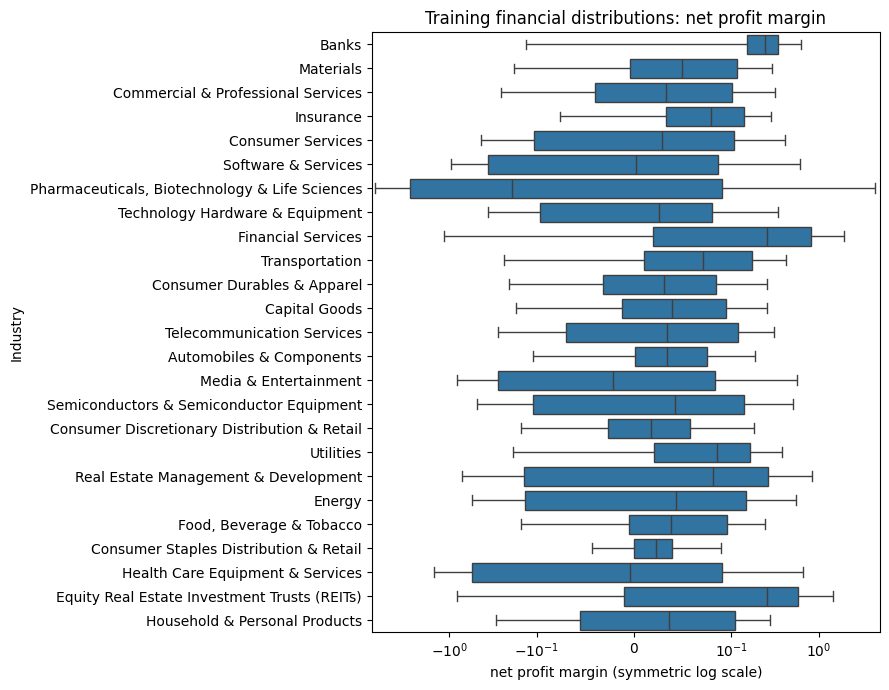

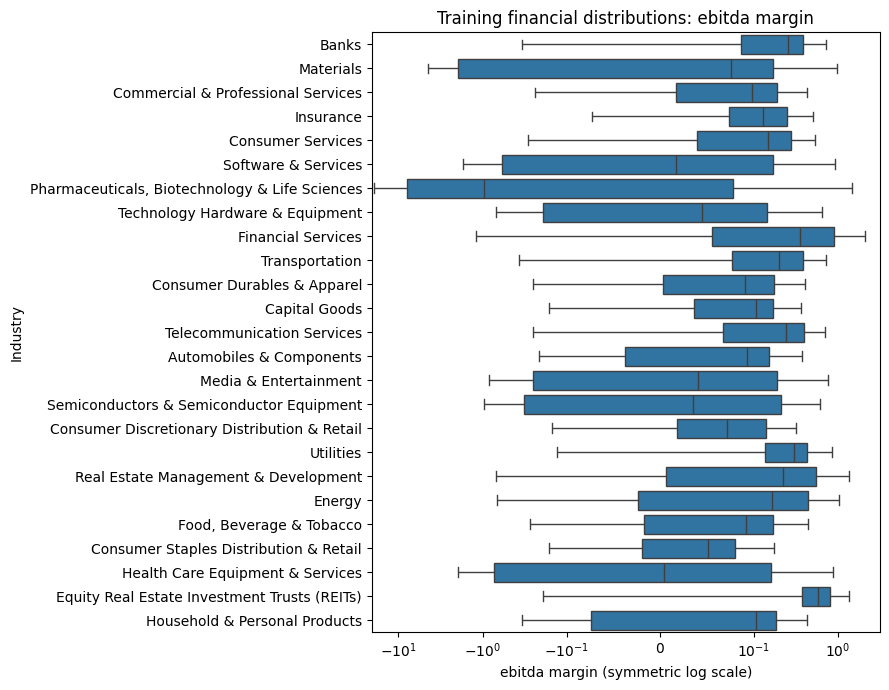

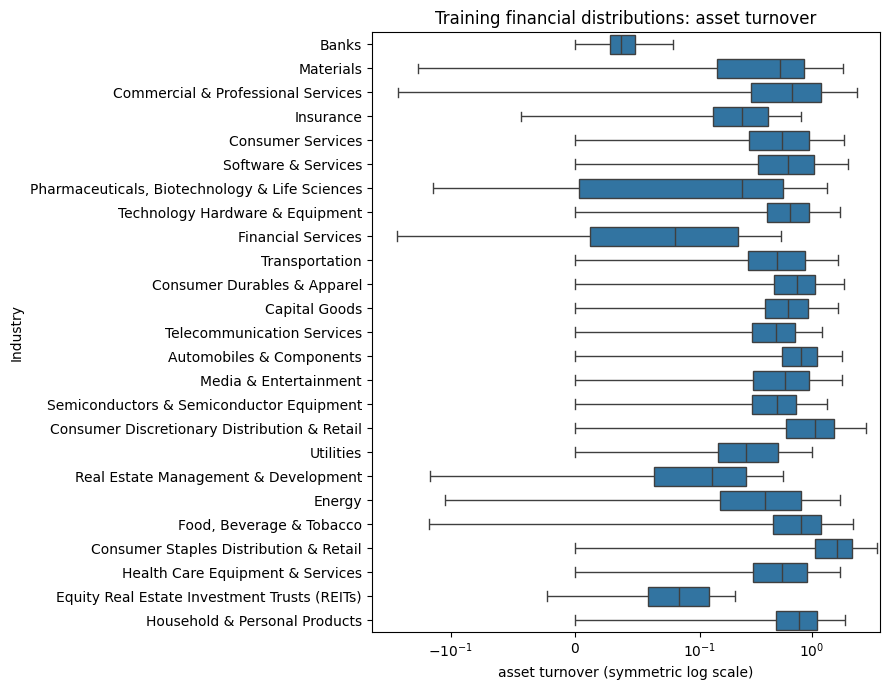

In [10]:
display(df_fit.groupby('industry')[financial_columns].agg(['count', 'median']))
for column in financial_columns:
    plt.figure(figsize=(9, 7))
    sns.boxplot(data=df_fit, x=column, y='industry', showfliers=False)
    plt.xscale('symlog', linthresh=0.1)
    plt.xlabel(column.replace('_', ' ') + ' (symmetric log scale)')
    plt.ylabel('Industry')
    plt.title('Training financial distributions: ' + column.replace('_', ' '))
    plt.tight_layout()
    plt.show()


### Combining text predictions with financial evidence

Combine aligned industry-probability vectors using the tuning-selected weight:
this is soft voting. Weight selection never uses the confidence-calibration or
final-validation labels.
Financial information adjusts confidence rather than changing the chosen industry.

For each industry and ratio, sort the fitting companies' finite financial values.
A new observation's percentile describes its position in that reference sample.
`2 × min(percentile, 1 − percentile)` is high near the middle and low in the tails.
Tied observations use their middle rank. A small offset keeps scores finite at
both extremes. Profiles with fewer than 20 observations are omitted.

Average the available ratios' scores. This is a **financial compatibility score**,
not a probability that an industry is correct and not a formal combined p-value.
Missing profiles contribute no evidence. When all are absent, use a placeholder
of 0.5 plus an availability value of 0, so absence can be distinguished from
observed compatibility of 0.5.

Confidence inputs are the largest vote probability, the gap to the next industry,
model agreement, financial compatibility, and the fraction of usable ratios.


    **Observed financial patterns.** The boxplots show broad overlapping ranges,
    especially for net profit margins. Pharmaceutical margins include substantial
    negative values, while Banks and REITs have much lower typical asset turnover
    than Consumer Staples Distribution & Retail. Financial ratios therefore provide
    supporting evidence rather than deterministic industry rules. The raw-quality
    table reports 19,279 missing EBITDA margins out of 29,561 financial records
    (65.2%), before also treating infinities as missing; coverage is uneven.


In [11]:
profiles = {}
for industry in le.classes_:
    for column in financial_columns:
        reference = df_fit.loc[df_fit['industry'] == industry, column].dropna().to_numpy()
        profiles[industry, column] = np.sort(reference)

def confidence_features(companies, proba_lr, proba_knn):
    votes = lr_weight * proba_lr + (1 - lr_weight) * proba_knn
    prediction = votes.argmax(axis=1)
    top = np.sort(votes, axis=1)
    agreement = proba_lr.argmax(axis=1) == proba_knn.argmax(axis=1)
    predicted_industries = le.inverse_transform(prediction)
    total = np.zeros(len(companies))
    available = np.zeros(len(companies))
    for industry in le.classes_:
        for column in financial_columns:
            reference = profiles[industry, column]
            if len(reference) < 20:
                continue
            values = companies[column].to_numpy()
            mask = (predicted_industries == industry) & np.isfinite(values)
            left = np.searchsorted(reference, values[mask], side='left')
            right = np.searchsorted(reference, values[mask], side='right')
            percentile = (0.5 * (left + right) + 0.5) / (len(reference) + 1)
            total[mask] += 2 * np.minimum(percentile, 1 - percentile)
            available[mask] += 1
    compatibility = np.divide(total, available, out=np.full(len(companies), 0.5), where=available > 0)
    features = np.column_stack([top[:, -1], top[:, -1] - top[:, -2],
                                agreement, compatibility, available / len(financial_columns)])
    return prediction, features

pred_cal, features_cal = confidence_features(df_cal, proba_cal_lr, proba_cal_knn)
correct_cal = (pred_cal == y_cal).astype(int)
text_calibrator = LogisticRegression().fit(features_cal[:, :3], correct_cal)
finance_calibrator = LogisticRegression().fit(features_cal, correct_cal)
pred_val, features_val = confidence_features(df_val, proba_val_lr, proba_val_knn)


### Honest evaluation of confidence

The calibration models learn from the 4.5% calibration companies only. Their target
is whether the fixed ensemble prediction was correct. The text-only version
provides a direct comparison for the additional financial inputs.

Evaluate every approach on the same final validation companies. The three
ensemble variants have identical labels and F1; confidence affects their Brier
scores. Report all results rather than choosing a confidence method from this
validation and calling that choice independently validated.


In [12]:
confidence_methods = {
    'Raw ensemble': features_val[:, 0],
    'Text-calibrated ensemble': text_calibrator.predict_proba(features_val[:, :3])[:, 1],
    'Financial-calibrated ensemble': finance_calibrator.predict_proba(features_val)[:, 1]
}
bonus_results = []
for name, confidence in confidence_methods.items():
    bonus_results.append([name, f1_score(y_val, pred_val, average='weighted'),
                          np.mean((confidence - (pred_val == y_val)) ** 2),
                          confidence_score(y_val, pred_val, confidence)])
for name, probabilities in [('Logistic regression', proba_val_lr), ('k-NN', proba_val_knn)]:
    prediction = probabilities.argmax(axis=1)
    confidence = probabilities.max(axis=1)
    bonus_results.append([name, f1_score(y_val, prediction, average='weighted'),
                          np.mean((confidence - (prediction == y_val)) ** 2),
                          confidence_score(y_val, prediction, confidence)])
display(pd.DataFrame(bonus_results, columns=['Method', 'Weighted F1', 'Brier', 'Official score']).set_index('Method'))


,Weighted F1,Brier,Official score
Method,,,
Raw ensemble,0.780881,0.137380,0.673604
Text-calibrated ensemble,0.780881,0.135923,0.674742
Financial-calibrated ensemble,0.780881,0.135585,0.675006
Logistic regression,0.777788,0.137087,0.671163
k-NN,0.771401,0.141496,0.662251


### Confidence, accuracy, and human review

Fix the financial-calibrated ensemble as the bonus candidate before viewing the
validation results. Group its confidence into ten intervals and compare each
interval's average confidence with accuracy. Include counts: small bins are noisy.

Flag confidence below 0.8 for human review. This is an explicit starting policy,
not an instructor-mandated or validation-optimized threshold. All companies still
receive predictions; review flags do not remove difficult cases from the score.


,Count,Mean_confidence,Accuracy
Bin,,,
"(0.2, 0.3]",11,0.280748,0.363636
"(0.3, 0.4]",128,0.364461,0.437500
"(0.4, 0.5]",258,0.449690,0.449612
"(0.5, 0.6]",235,0.548473,0.557447
"(0.6, 0.7]",237,0.649352,0.628692
"(0.7, 0.8]",300,0.752414,0.723333
"(0.8, 0.9]",617,0.857856,0.820097
"(0.9, 1.0]",1385,0.937450,0.948736


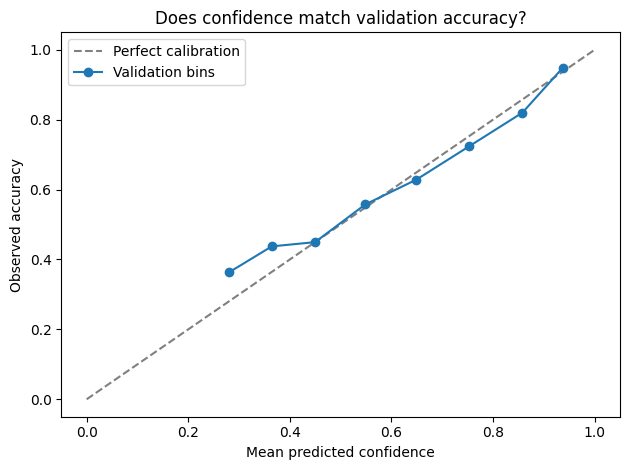

,Count,Accuracy
Human review,,
False,2002,0.909091
True,1169,0.575706


Companies flagged for review: 36.9%
Errors captured by review: 496 of 678


In [13]:
confidence_val = confidence_methods['Financial-calibrated ensemble']
outcomes = pd.DataFrame({'Confidence': confidence_val, 'Correct': pred_val == y_val})
outcomes['Bin'] = pd.cut(outcomes['Confidence'], np.linspace(0, 1, 11), include_lowest=True)
reliability = outcomes.groupby('Bin', observed=True).agg(
    Count=('Correct', 'size'), Mean_confidence=('Confidence', 'mean'), Accuracy=('Correct', 'mean')
)
display(reliability)
plt.plot([0, 1], [0, 1], '--', color='gray', label='Perfect calibration')
plt.plot(reliability['Mean_confidence'], reliability['Accuracy'], 'o-', label='Validation bins')
plt.xlabel('Mean predicted confidence')
plt.ylabel('Observed accuracy')
plt.title('Does confidence match validation accuracy?')
plt.legend()
plt.tight_layout()
plt.show()

review = confidence_val < 0.8
outcomes['Human review'] = review
display(outcomes.groupby('Human review').agg(Count=('Correct', 'size'), Accuracy=('Correct', 'mean')))
print('Companies flagged for review:', f'{review.mean():.1%}')
print('Errors captured by review:', np.sum(review & (pred_val != y_val)),
      'of', np.sum(pred_val != y_val))


### Prediction interface

`predict_industry` returns the required tuple of industry-name and confidence
vectors, in input-row order. Input companies need the embedding column and the
three financial columns; absent financial observations must be `NaN`.
If separate private-test financial data is supplied, resolve duplicate financial
IDs and join it exactly as above. This function does not read an industry target.

The course has not specified a private-test entry-point name or file format.
This simple interface can be adapted when those instructions are available.


In [14]:
def predict_industry(companies):
    X = embeddings(companies)
    prediction, features = confidence_features(
        companies, lr.predict_proba(X), knn.predict_proba(pca.transform(X))
    )
    confidence = finance_calibrator.predict_proba(features)[:, 1]
    return le.inverse_transform(prediction), confidence

example = df_val.drop(columns='industry').head(3)
predicted_industries, confidences = predict_industry(example)
display(pd.DataFrame({'ID': example['id'].to_numpy(),
                      'Predicted industry': predicted_industries, 'Confidence': confidences}))
seen_embedding = df_val['business_description_embedding'].isin(df_fit['business_description_embedding'])
display(pd.DataFrame({'Embedding seen during fitting': seen_embedding.to_numpy(),
                      'Correct': pred_val == y_val}).groupby('Embedding seen during fitting').agg(
                          Count=('Correct', 'size'), Accuracy=('Correct', 'mean')))
print('Whole notebook elapsed seconds:', round(perf_counter() - started, 1))


,ID,Predicted industry,Confidence
0,21057,Capital Goods,0.710822
1,24720,Materials,0.950146
2,24392,Consumer Services,0.908970


,Count,Accuracy
Embedding seen during fitting,,
False,2716,0.751473
True,455,0.993407


Whole notebook elapsed seconds: 77.9


### Results and limitations

**Confidence and finances.** Raw ensemble Brier is 0.13738; text calibration
reduces it to 0.13592 and adding financial evidence to 0.13558. Official scores
are 67.36%, 67.47%, and 67.50%, respectively. The financial improvement over
text calibration is only 0.03 percentage points on this split; it does not
establish a robust advantage on other data. Financial inputs affect confidence,
so all three variants retain 78.09% weighted F1 and 78.62% accuracy.

**Confidence and review.** For the 1,385 predictions in the highest bin, mean
confidence is 93.74% and accuracy is 94.87%. In the 0.8–0.9 bin, mean confidence
is 85.79% but accuracy is 82.01%, showing some overconfidence. The smallest bin
has only 11 observations and is noisy. Confidence below 0.8 flags 1,169 records
(36.9%); their accuracy is 57.57%, versus 90.91% among unflagged records. Review
flags capture 496 of 678 errors (73.2%). Human review is a workload policy,
not a way to remove errors from the evaluation.

**Repeated descriptions.** Company IDs are disjoint, but 455 validation records
(14.35%) have exact embedding strings seen during fitting. Ensemble accuracy
is 99.34% on those and 75.15% on the 2,716 unseen-description records. The
overall score therefore estimates performance on unseen company IDs rather
than entirely unseen descriptions. Seventeen identical-embedding groups in
the full dataset also have conflicting industry labels.

**Target and resources.** The local 85% bonus target was not reached. Since the
official score cannot exceed weighted F1, confidence adjustments alone cannot
reach 85% with these validation predictions. No private-test score or grading
outcome is claimed. PCA and base-classifier fitting took 12.1 seconds; the
notebook reports 77.9 seconds through its last code cell. The external runner,
including additional checks, took 81.5 seconds with a runner-plus-kernel peak
memory upper bound of 1.37 GiB. These are cloud measurements, not an Intel Mac
benchmark. The 45-minute laptop limit remains unverified on that machine.

AI assistance was used with the student's stated permission. The accompanying
notes explain the implementation and provide oral-exam practice questions.
